# 📐 Principal Component Analysis (PCA) using SVD & EVD

### A Step-by-Step Visual Tutorial

---

> **"The goal of PCA is to find a new coordinate system aligned with the directions of maximum variance in your data."**

---

## 🗺️ What You'll Learn

| Section | Topic |
|--------|-------|
| 1 | Why do we need dimensionality reduction? |
| 2 | Intuition behind PCA |
| 3 | The math: Covariance matrix & Eigendecomposition |
| 4 | Singular Value Decomposition (SVD) — explained |
| 5 | The bridge: How SVD gives us PCA |
| 6 | From scratch: PCA with SVD in NumPy |
| 7 | Real-world example: Faces dataset |
| 8 | Choosing the number of components |
| 9 | PCA vs `sklearn` — sanity check |

---

## 📦 Requirements

```
numpy, matplotlib, seaborn, sklearn, pandas
```

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pandas as pd
import matplotlib as mpl
from sklearn.datasets import load_digits, fetch_olivetti_faces
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA as skPCA
from mpl_toolkits.mplot3d import Axes3D

# Aesthetics
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 13
sns.set_style('whitegrid')
np.random.seed(42)

print('✅ All libraries loaded successfully!')

✅ All libraries loaded successfully!


---
## 1. 🤔 Why Dimensionality Reduction?

Modern datasets are **high-dimensional** — images, genomics data, text embeddings, sensor readings. Working with all these dimensions creates problems:

- 🐌 **Slow computation** — algorithms scale poorly with many features
- 📉 **Curse of dimensionality** — data becomes sparse; distances lose meaning
- 👁️ **No visualization** — we can't see beyond 3D
- 🔁 **Redundancy** — many features are highly correlated

**Dimensionality reduction** compresses data into fewer dimensions while retaining as much information (variance) as possible.

### Toy Example: Correlated 2D Data

If height and weight are highly correlated, we don't need both — one new axis captures almost all the information.

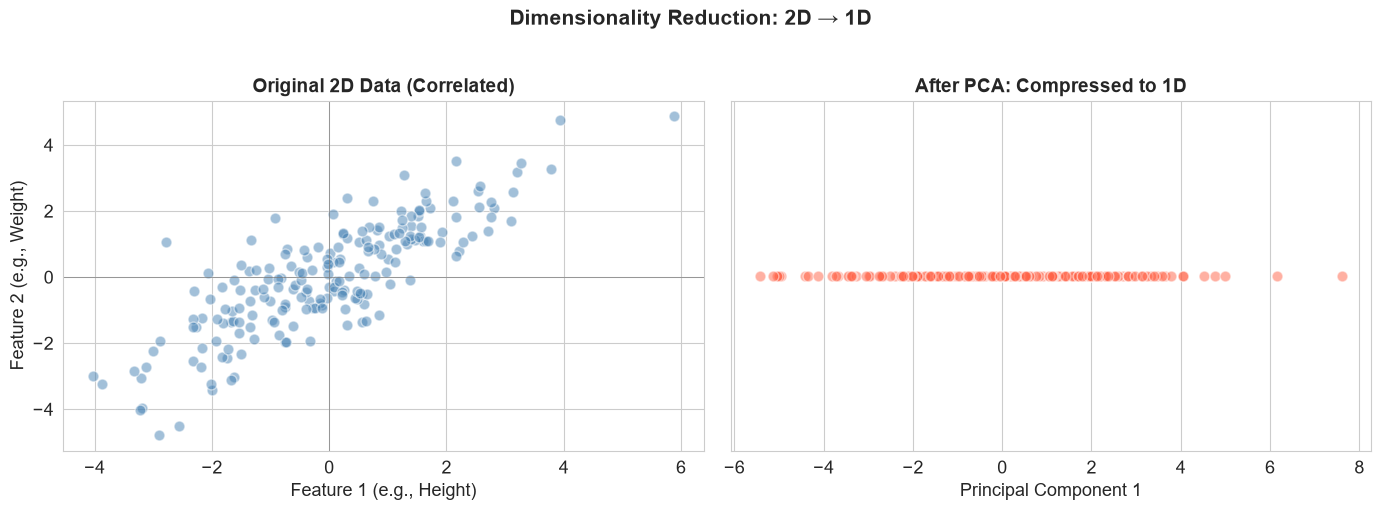


📊 Variance retained by PC1: 91.6%


In [17]:
# Generate correlated 2D data
mean = [0, 0]
cov = [[3, 2.5], [2.5, 3]]   # high correlation
X_2d = np.random.multivariate_normal(mean, cov, 200)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: raw data
axes[0].scatter(X_2d[:, 0], X_2d[:, 1], alpha=0.5, color='steelblue', edgecolors='white', s=60)
axes[0].set_title('Original 2D Data (Correlated)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Feature 1 (e.g., Height)')
axes[0].set_ylabel('Feature 2 (e.g., Weight)')
axes[0].axhline(0, color='gray', lw=0.5)
axes[0].axvline(0, color='gray', lw=0.5)

# Right: after PCA — project to 1D
U, S, Vt = np.linalg.svd(X_2d - X_2d.mean(axis=0), full_matrices=False)
X_1d = U[:, 0:1] * S[0]

axes[1].scatter(X_1d[:, 0], np.zeros(len(X_1d)), alpha=0.5, color='tomato', edgecolors='white', s=60)
axes[1].set_title('After PCA: Compressed to 1D', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_yticks([])
axes[1].set_ylabel('')

plt.suptitle('Dimensionality Reduction: 2D → 1D', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Compute variance retained
var_total = np.var(X_2d, axis=0).sum()
var_pc1 = np.var(X_1d)
print(f'\n📊 Variance retained by PC1: {var_pc1/var_total*100:.1f}%')

---
## 2. 💡 Intuition Behind PCA

PCA answers one question:

> **"What directions in my data have the most spread (variance)?"**

Imagine shining a flashlight on a cloud of 3D points and looking at the shadow — PCA finds the angle that gives the **largest, most informative shadow**.

### Key Ideas

- **Principal Component 1 (PC1)**: The direction of **maximum variance**
- **Principal Component 2 (PC2)**: The direction of maximum variance **orthogonal** to PC1
- And so on...

Each PC is a **linear combination** of the original features:

$$\text{PC}_1 = w_{11} x_1 + w_{12} x_2 + \cdots + w_{1p} x_p$$

where the weights $\mathbf{w}_1$ are chosen to **maximize variance** subject to $\|\mathbf{w}_1\| = 1$.

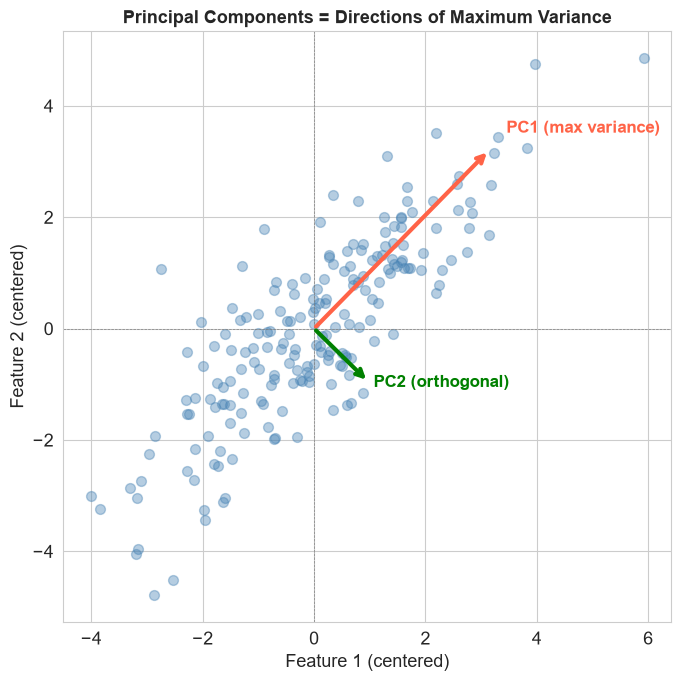

PC1 direction: [0.700, 0.714]
PC2 direction: [0.714, -0.700]
PC1 · PC2 = 0.000000  ← orthogonal! (dot product ≈ 0)


In [18]:
# Visualize PCA directions on 2D data
X = X_2d.copy()
X_centered = X - X.mean(axis=0)

# Compute PCA via SVD
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
components = Vt  # rows are principal components

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(X_centered[:, 0], X_centered[:, 1], alpha=0.4, s=50, color='steelblue', label='Data points')

# Draw principal component directions
scale = [S[0]/np.sqrt(len(X)), S[1]/np.sqrt(len(X))]
colors = ['tomato', 'green']
labels = ['PC1 (max variance)', 'PC2 (orthogonal)']

for i in range(2):
    ax.annotate('',
                xy=(components[i, 0] * scale[i] * 2, components[i, 1] * scale[i] * 2),
                xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=colors[i], lw=3))
    ax.text(components[i, 0] * scale[i] * 2.2, components[i, 1] * scale[i] * 2.2,
            labels[i], color=colors[i], fontsize=12, fontweight='bold')

ax.set_title('Principal Components = Directions of Maximum Variance', fontsize=13, fontweight='bold')
ax.set_xlabel('Feature 1 (centered)')
ax.set_ylabel('Feature 2 (centered)')
ax.axhline(0, color='gray', lw=0.5, linestyle='--')
ax.axvline(0, color='gray', lw=0.5, linestyle='--')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

print(f'PC1 direction: [{components[0,0]:.3f}, {components[0,1]:.3f}]')
print(f'PC2 direction: [{components[1,0]:.3f}, {components[1,1]:.3f}]')
print(f'PC1 · PC2 = {np.dot(components[0], components[1]):.6f}  ← orthogonal! (dot product ≈ 0)')

---
## 3. 🧮 The Math: Covariance Matrix & Eigendecomposition

### Step 1: Center the data

Subtract the mean from every feature:
$$\tilde{X} = X - \bar{X}$$

### Step 2: Compute the Covariance Matrix

For a data matrix $\tilde{X}$ of shape $(n \times p)$:

$$\Sigma = \frac{1}{n-1} \tilde{X}^T \tilde{X}$$

The covariance matrix $\Sigma$ is:
- **Symmetric**: $\Sigma = \Sigma^T$
- **Positive semi-definite**: all eigenvalues $\geq 0$
- **$(p \times p)$** — one row/col per feature

### Step 3: Eigendecomposition

$$\Sigma \mathbf{v} = \lambda \mathbf{v}$$

- **Eigenvectors** $\mathbf{v}$: the principal component directions
- **Eigenvalues** $\lambda$: the variance explained by each component

$$\Sigma = V \Lambda V^T$$

where $V$ contains eigenvectors as columns, $\Lambda$ is diagonal with eigenvalues.

In [19]:
# ---- PCA via Eigendecomposition of Covariance Matrix ----

# Step 1: Center
X_c = X_2d - X_2d.mean(axis=0)
print('✅ Step 1: Data centered')
print(f'   Mean after centering: {X_c.mean(axis=0).round(10)}')

# Step 2: Covariance matrix
n = X_c.shape[0]
Sigma = (X_c.T @ X_c) / (n - 1)
print(f'\n✅ Step 2: Covariance matrix (shape {Sigma.shape}):')
print(np.round(Sigma, 3))

# Step 3: Eigendecomposition
eigenvalues, eigenvectors = np.linalg.eigh(Sigma)  # eigh for symmetric

# Sort descending
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print(f'\n✅ Step 3: Eigendecomposition')
print(f'   Eigenvalues (= variance per PC): {eigenvalues.round(3)}')
print(f'   Eigenvectors (columns = PC directions):')
print(eigenvectors.round(3))

# Variance explained
var_explained = eigenvalues / eigenvalues.sum() * 100
print(f'\n📊 Variance explained:')
for i, v in enumerate(var_explained):
    print(f'   PC{i+1}: {v:.1f}%')

✅ Step 1: Data centered
   Mean after centering: [0. 0.]

✅ Step 2: Covariance matrix (shape (2, 2)):
[[2.712 2.29 ]
 [2.29  2.799]]

✅ Step 3: Eigendecomposition
   Eigenvalues (= variance per PC): [5.046 0.465]
   Eigenvectors (columns = PC directions):
[[ 0.7   -0.714]
 [ 0.714  0.7  ]]

📊 Variance explained:
   PC1: 91.6%
   PC2: 8.4%


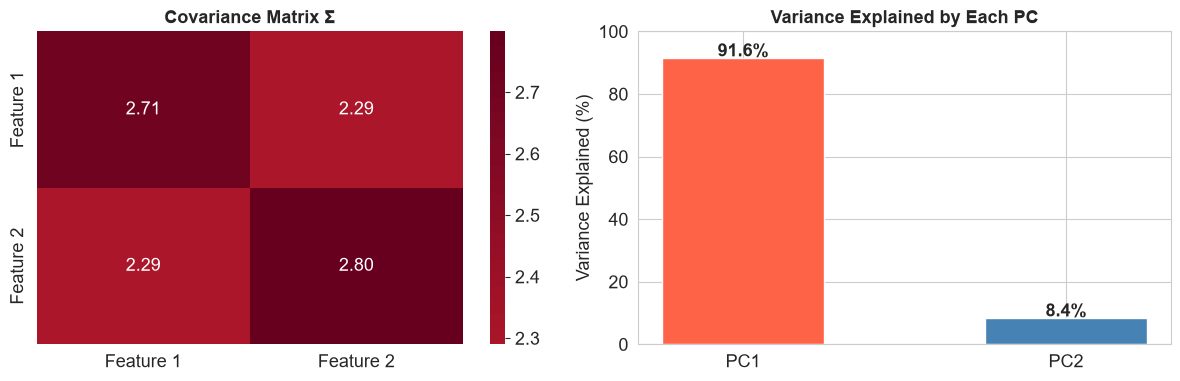

In [20]:
# Visualize the covariance matrix as a heatmap
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Covariance matrix
sns.heatmap(Sigma, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            xticklabels=['Feature 1', 'Feature 2'],
            yticklabels=['Feature 1', 'Feature 2'], ax=axes[0])
axes[0].set_title('Covariance Matrix Σ', fontsize=13, fontweight='bold')

# Variance explained bar chart
axes[1].bar(['PC1', 'PC2'], var_explained, color=['tomato', 'steelblue'], edgecolor='white', width=0.5)
axes[1].set_ylabel('Variance Explained (%)')
axes[1].set_title('Variance Explained by Each PC', fontsize=13, fontweight='bold')
for i, v in enumerate(var_explained):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

---
## 4. ✂️ Singular Value Decomposition (SVD)

SVD is one of the most important matrix factorizations in all of linear algebra. For **any** matrix $X$ of shape $(n \times p)$:

$$\boxed{X = U \Sigma V^T}$$

| Symbol | Shape | Meaning |
|--------|-------|---------|
| $U$ | $n \times n$ | **Left singular vectors** (rotate/reflect the data) |
| $\Sigma$ | $n \times p$ (diagonal) | **Singular values** (how much each direction matters) |
| $V^T$ | $p \times p$ | **Right singular vectors** (the new axes / PC directions) |

### Properties
- $U$ and $V$ are **orthogonal**: $U^T U = I$, $V^T V = I$
- Singular values $\sigma_1 \geq \sigma_2 \geq \cdots \geq 0$ are always non-negative
- **Thin (economy) SVD**: For $n > p$, we only need $U$ of shape $(n \times p)$

### Geometric Interpretation

SVD decomposes any linear transformation into three steps:
1. **Rotate** (by $V^T$)
2. **Scale** (by $\Sigma$)
3. **Rotate** (by $U$)

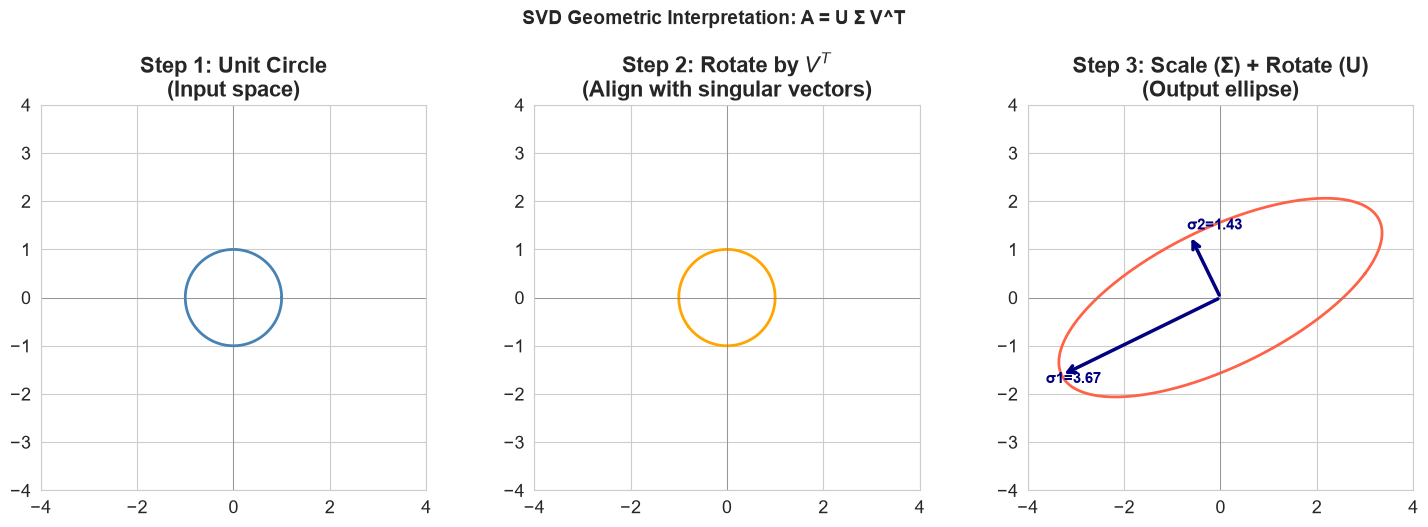

Matrix A decomposed into:
  U (left singular vectors):
[[-0.898 -0.439]
 [-0.439  0.898]]
  Σ (singular values): [3.668 1.431]
  Vt (right singular vectors):
[[-0.795 -0.607]
 [-0.607  0.795]]


In [21]:
# Demonstrate SVD geometrically on a unit circle
theta = np.linspace(0, 2 * np.pi, 300)
circle = np.vstack([np.cos(theta), np.sin(theta)])  # (2, 300)

# A 2x2 transformation matrix
A = np.array([[3, 1.5],
              [0.5, 2]])

# Apply transformation
ellipse = A @ circle

# SVD of A
U_A, S_A, Vt_A = np.linalg.svd(A)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].plot(circle[0], circle[1], 'steelblue', lw=2)
axes[0].set_title('Step 1: Unit Circle\n(Input space)', fontweight='bold')
axes[0].set_xlim(-4, 4); axes[0].set_ylim(-4, 4)
axes[0].axhline(0, color='gray', lw=0.5); axes[0].axvline(0, color='gray', lw=0.5)
axes[0].set_aspect('equal')

# After Vt rotation
rotated = Vt_A @ circle
axes[1].plot(rotated[0], rotated[1], 'orange', lw=2, label='V^T · circle')
axes[1].set_title('Step 2: Rotate by $V^T$\n(Align with singular vectors)', fontweight='bold')
axes[1].set_xlim(-4, 4); axes[1].set_ylim(-4, 4)
axes[1].axhline(0, color='gray', lw=0.5); axes[1].axvline(0, color='gray', lw=0.5)
axes[1].set_aspect('equal')

# Final ellipse
axes[2].plot(ellipse[0], ellipse[1], 'tomato', lw=2)
# Draw singular vector directions scaled by singular values
for i in range(2):
    axes[2].annotate('', xy=(U_A[:, i] * S_A[i]), xytext=(0, 0),
                     arrowprops=dict(arrowstyle='->', color='navy', lw=2.5))
    axes[2].text(U_A[0, i] * S_A[i] * 1.1, U_A[1, i] * S_A[i] * 1.1,
                 f'σ{i+1}={S_A[i]:.2f}', fontsize=11, color='navy', fontweight='bold')
axes[2].set_title('Step 3: Scale (Σ) + Rotate (U)\n(Output ellipse)', fontweight='bold')
axes[2].set_xlim(-4, 4); axes[2].set_ylim(-4, 4)
axes[2].axhline(0, color='gray', lw=0.5); axes[2].axvline(0, color='gray', lw=0.5)
axes[2].set_aspect('equal')

plt.suptitle('SVD Geometric Interpretation: A = U Σ V^T', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print(f'Matrix A decomposed into:')
print(f'  U (left singular vectors):\n{U_A.round(3)}')
print(f'  Σ (singular values): {S_A.round(3)}')
print(f'  Vt (right singular vectors):\n{Vt_A.round(3)}')

---
## 5. 🌉 The Bridge: How SVD Gives Us PCA

This is the key insight. Let's see why SVD on the **centered data matrix** is equivalent to eigendecomposition of the **covariance matrix**.

Given centered data $\tilde{X}$ of shape $(n \times p)$, apply SVD:

$$\tilde{X} = U \Sigma V^T$$

Now compute the covariance matrix:

$$\Sigma_{\text{cov}} = \frac{1}{n-1} \tilde{X}^T \tilde{X} = \frac{1}{n-1} (U \Sigma V^T)^T (U \Sigma V^T)$$

$$= \frac{1}{n-1} V \Sigma^T \underbrace{U^T U}_{= I} \Sigma V^T = \frac{1}{n-1} V \Sigma^2 V^T$$

Comparing with eigendecomposition $\Sigma_{\text{cov}} = V \Lambda V^T$:

$$\boxed{\lambda_i = \frac{\sigma_i^2}{n-1}}$$

### Conclusion

| From SVD | Meaning in PCA |
|----------|----------------|
| Rows of $V^T$ | **Principal component directions** (eigenvectors of $\Sigma_{\text{cov}}$) |
| $\sigma_i^2 / (n-1)$ | **Variance** explained by PC$_i$ (eigenvalues of $\Sigma_{\text{cov}}$) |
| Columns of $U\Sigma$ | **Projected scores** (coordinates in PC space) |

In [22]:
# ---- Verify the math: SVD eigenvalues == covariance eigenvalues ----
print('='*55)
print('Verifying: SVD singular values ↔ Covariance eigenvalues')
print('='*55)

X_c = X_2d - X_2d.mean(axis=0)
n = X_c.shape[0]

# Method A: Eigendecomposition of covariance
Cov = X_c.T @ X_c / (n - 1)
eig_vals, eig_vecs = np.linalg.eigh(Cov)
eig_vals = eig_vals[::-1]
eig_vecs = eig_vecs[:, ::-1]

# Method B: SVD of centered data
U_svd, S_svd, Vt_svd = np.linalg.svd(X_c, full_matrices=False)
svd_eig_vals = S_svd**2 / (n - 1)   # convert singular values → eigenvalues

print(f'\nEigenvalues from covariance matrix: {eig_vals.round(4)}')
print(f'Eigenvalues from SVD (σ²/n-1):     {svd_eig_vals.round(4)}')
print(f'\nMatch: {np.allclose(eig_vals, svd_eig_vals)} ✅')

print(f'\nPC directions from eigenvectors:\n{np.abs(eig_vecs.T).round(4)}')
print(f'PC directions from SVD (Vt):\n{np.abs(Vt_svd).round(4)}')
print(f'\nDirections match (up to sign): {np.allclose(np.abs(eig_vecs.T), np.abs(Vt_svd))} ✅')

Verifying: SVD singular values ↔ Covariance eigenvalues

Eigenvalues from covariance matrix: [5.046  0.4651]
Eigenvalues from SVD (σ²/n-1):     [5.046  0.4651]

Match: True ✅

PC directions from eigenvectors:
[[0.7004 0.7138]
 [0.7138 0.7004]]
PC directions from SVD (Vt):
[[0.7004 0.7138]
 [0.7138 0.7004]]

Directions match (up to sign): True ✅


---
## 6. 🛠️ PCA from Scratch with SVD (Step-by-Step)

Now let's implement a clean, reusable PCA function using SVD, and apply it to a 3D dataset that we'll reduce to 2D.

In [23]:
class PCA_SVD:
    """
    Principal Component Analysis using Singular Value Decomposition.
    Built from scratch using NumPy only.
    """

    def __init__(self, n_components):
        self.n_components = n_components
        self.mean_ = None
        self.components_ = None       # rows = PC directions (Vt rows)
        self.singular_values_ = None
        self.explained_variance_ = None
        self.explained_variance_ratio_ = None

    def fit(self, X):
        """Compute principal components from data X."""
        n, p = X.shape

        # Step 1: Center the data
        self.mean_ = X.mean(axis=0)
        X_c = X - self.mean_

        # Step 2: Thin SVD
        U, S, Vt = np.linalg.svd(X_c, full_matrices=False)

        # Step 3: Keep top k components
        self.components_ = Vt[:self.n_components]          # shape: (k, p)
        self.singular_values_ = S[:self.n_components]

        # Step 4: Compute explained variance
        self.explained_variance_ = S**2 / (n - 1)
        total_var = self.explained_variance_.sum()
        self.explained_variance_ratio_ = self.explained_variance_[:self.n_components] / total_var

        return self

    def transform(self, X):
        """Project X onto the principal components."""
        X_c = X - self.mean_
        return X_c @ self.components_.T    # shape: (n, k)

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, X_transformed):
        """Reconstruct approximate original data from PC scores."""
        return X_transformed @ self.components_ + self.mean_

print('✅ PCA_SVD class defined!')

✅ PCA_SVD class defined!


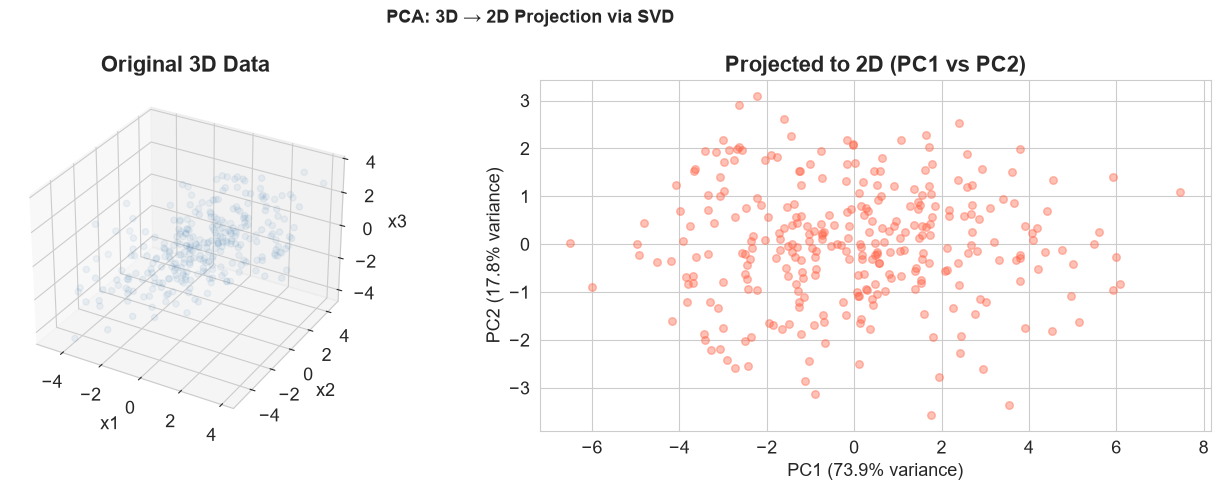


📊 Total variance retained: 91.7%
   PC1: 73.9%
   PC2: 17.8%


In [24]:
# Apply PCA_SVD to 3D → 2D

# Generate 3D correlated data
cov_3d = np.array([[3, 2,  1],
                   [2, 3,  1.5],
                   [1, 1.5, 2]])
X_3d = np.random.multivariate_normal([0, 0, 0], cov_3d, 300)

# PCA: 3D → 2D
pca = PCA_SVD(n_components=2)
X_proj = pca.fit_transform(X_3d)

# Plot
fig = plt.figure(figsize=(14, 5))

# 3D original
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2], alpha=0.3, s=20, color='steelblue')
ax1.set_title('Original 3D Data', fontweight='bold')
ax1.set_xlabel('x1'); ax1.set_ylabel('x2'); ax1.set_zlabel('x3')

# 2D projected
ax2 = fig.add_subplot(122)
ax2.scatter(X_proj[:, 0], X_proj[:, 1], alpha=0.4, s=30, color='tomato')
ax2.set_title('Projected to 2D (PC1 vs PC2)', fontweight='bold')
ax2.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax2.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')

plt.suptitle('PCA: 3D → 2D Projection via SVD', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

total_retained = pca.explained_variance_ratio_.sum()
print(f'\n📊 Total variance retained: {total_retained*100:.1f}%')
print(f'   PC1: {pca.explained_variance_ratio_[0]*100:.1f}%')
print(f'   PC2: {pca.explained_variance_ratio_[1]*100:.1f}%')

---
## 7. 🌍 Real-World Example: Handwritten Digits

Let's apply PCA to the **Digits dataset** — 1,797 images of handwritten digits (0–9), each 8×8 pixels = **64 features**.

We'll compress from 64D down to 2D for visualization, then explore reconstruction quality at different numbers of components.

Dataset shape: (1797, 64)
Classes: [0 1 2 3 4 5 6 7 8 9]
Features: 64 (= 8x8 pixels)


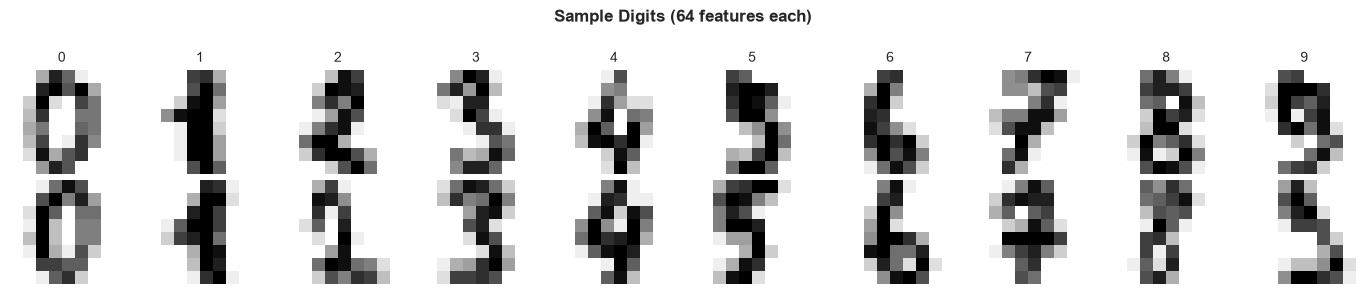

In [25]:
# Load digits dataset
digits = load_digits()
X_digits = digits.data        # (1797, 64)
y_digits = digits.target

print(f'Dataset shape: {X_digits.shape}')
print(f'Classes: {np.unique(y_digits)}')
print(f'Features: {X_digits.shape[1]} (= 8x8 pixels)')

# Show a few sample images
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for digit in range(10):
    idx = np.where(y_digits == digit)[0][0]
    axes[0, digit].imshow(X_digits[idx].reshape(8, 8), cmap='gray_r')
    axes[0, digit].set_title(str(digit), fontsize=10)
    axes[0, digit].axis('off')
    idx2 = np.where(y_digits == digit)[0][1]
    axes[1, digit].imshow(X_digits[idx2].reshape(8, 8), cmap='gray_r')
    axes[1, digit].axis('off')

plt.suptitle('Sample Digits (64 features each)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

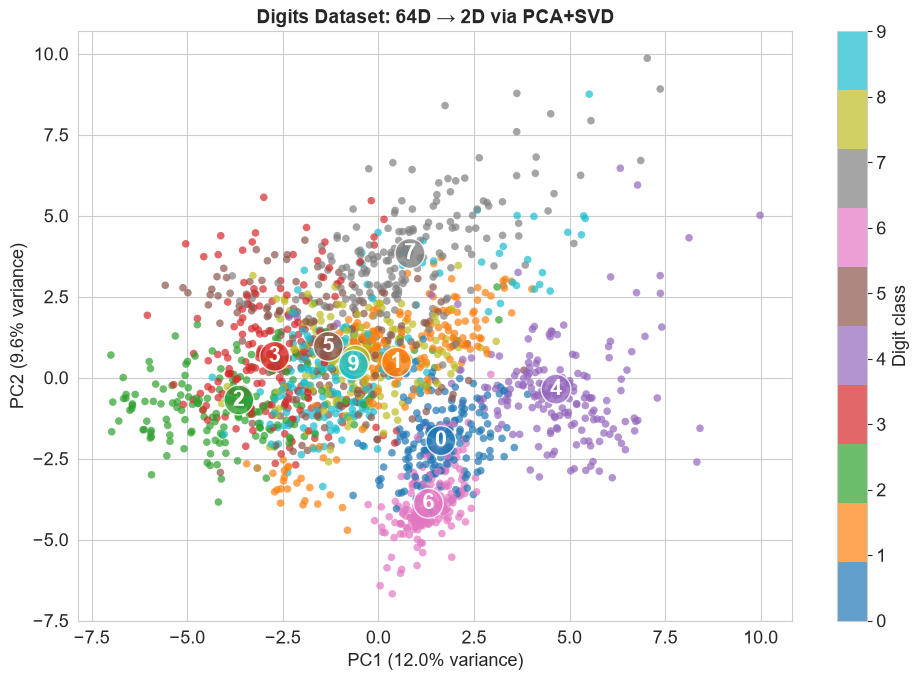

Variance retained in 2D: 21.6%


In [28]:
# PCA: 64D → 2D for visualization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_digits)

pca_2d = PCA_SVD(n_components=2)
X_2comp = pca_2d.fit_transform(X_scaled)

# Color map
cmap = mpl.colormaps['tab10'].resampled(10)

fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(X_2comp[:, 0], X_2comp[:, 1],
                     c=y_digits, cmap='tab10', alpha=0.7, s=30, edgecolors='none')

# Add digit labels at cluster centers
for digit in range(10):
    mask = y_digits == digit
    cx, cy = X_2comp[mask, 0].mean(), X_2comp[mask, 1].mean()
    ax.text(cx, cy, str(digit), fontsize=16, fontweight='bold',
            ha='center', va='center', color='white',
            bbox=dict(boxstyle='circle,pad=0.2', facecolor=cmap(digit), alpha=0.8))

ax.set_title('Digits Dataset: 64D → 2D via PCA+SVD', fontsize=14, fontweight='bold')
ax.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.colorbar(scatter, label='Digit class')
plt.tight_layout()
plt.show()

print(f'Variance retained in 2D: {pca_2d.explained_variance_ratio_.sum()*100:.1f}%')

C:\Users\Muhammad Taha\AppData\Local\Temp\ipykernel_15896\160048153.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


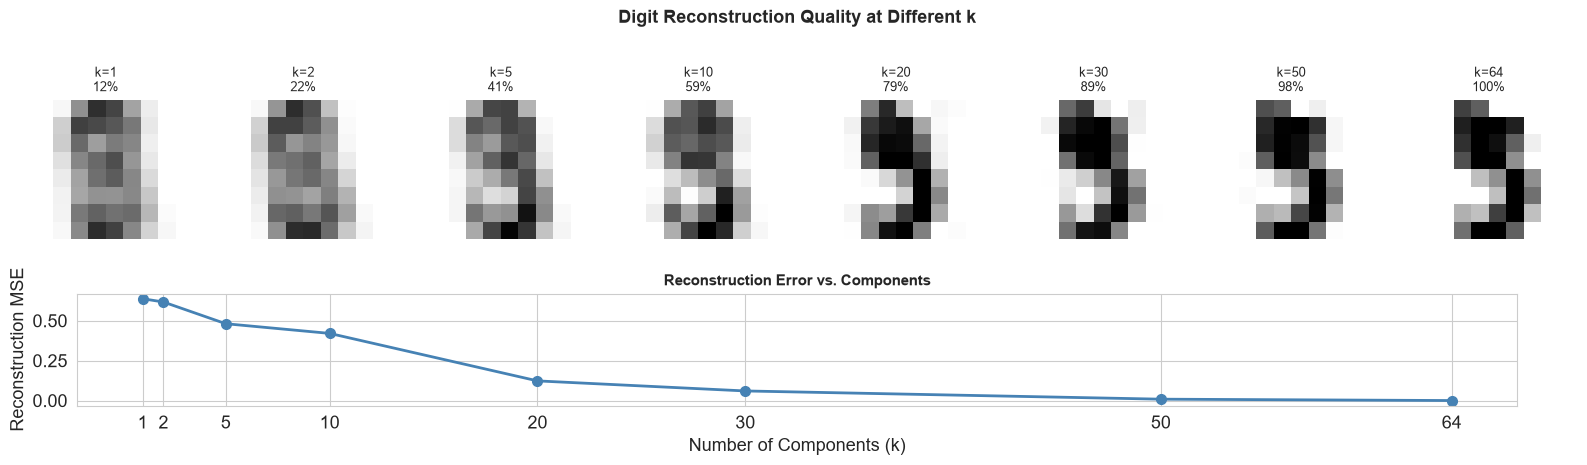

In [30]:
# Image reconstruction at different k values
sample_idx = np.where(y_digits == 5)[0][0]  # pick a '3'
x_sample = X_scaled[sample_idx:sample_idx+1]

k_values = [1, 2, 5, 10, 20, 30, 50, 64]
fig, axes = plt.subplots(2, len(k_values), figsize=(16, 4))

for col, k in enumerate(k_values):
    pca_k = PCA_SVD(n_components=k)
    pca_k.fit(X_scaled)

    x_proj = pca_k.transform(x_sample)
    x_recon = pca_k.inverse_transform(x_proj)

    img = scaler.inverse_transform(x_recon).reshape(8, 8)
    var_ret = pca_k.explained_variance_ratio_.sum()

    axes[0, col].imshow(img, cmap='gray_r', vmin=0, vmax=16)
    axes[0, col].set_title(f'k={k}\n{var_ret*100:.0f}%', fontsize=9)
    axes[0, col].axis('off')

# Error bar in row 2
errors = []
for k in k_values:
    pca_k = PCA_SVD(n_components=k)
    pca_k.fit(X_scaled)
    x_proj = pca_k.transform(x_sample)
    x_recon = pca_k.inverse_transform(x_proj)
    err = np.mean((x_sample - x_recon)**2)
    errors.append(err)

ax_err = axes[1, :]
for a in ax_err:
    a.axis('off')

# Draw error plot spanning the whole bottom
ax_big = fig.add_axes([0.05, 0.02, 0.9, 0.28])
ax_big.plot(k_values, errors, 'o-', color='steelblue', lw=2, markersize=7)
ax_big.set_xlabel('Number of Components (k)')
ax_big.set_ylabel('Reconstruction MSE')
ax_big.set_title('Reconstruction Error vs. Components', fontsize=11, fontweight='bold')
ax_big.set_xticks(k_values)

plt.suptitle('Digit Reconstruction Quality at Different k', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## 8. 📈 Choosing the Number of Components: Explained Variance Plot

A key practical question: **how many components should I keep?**

### The Scree Plot & Cumulative Variance

Common rules of thumb:
- Keep components until **80–95% of variance** is explained
- Look for the **"elbow"** in the scree plot — the point where adding more components gives diminishing returns

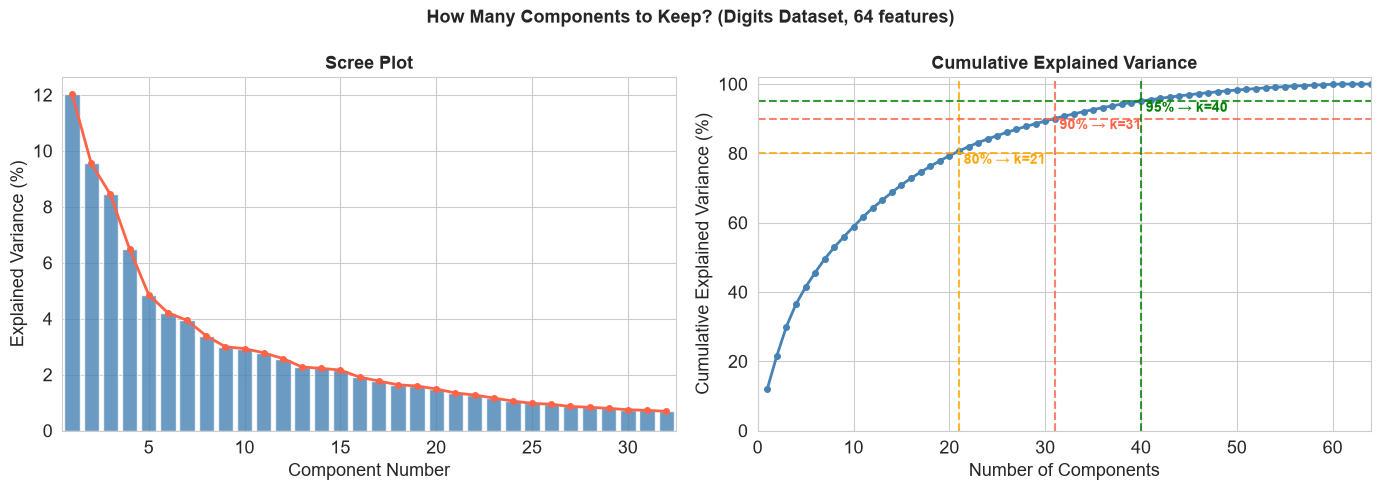

  80% variance → keep 21 components (reduce 64D → 21D, 33% of features)
  90% variance → keep 31 components (reduce 64D → 31D, 48% of features)
  95% variance → keep 40 components (reduce 64D → 40D, 62% of features)


In [31]:
# Full SVD to get all eigenvalues
_, S_all, _ = np.linalg.svd(X_scaled, full_matrices=False)
explained_variance_full = S_all**2 / (len(X_scaled) - 1)
explained_ratio = explained_variance_full / explained_variance_full.sum()
cumulative = np.cumsum(explained_ratio)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot (individual variance)
axes[0].bar(range(1, 33), explained_ratio[:32] * 100, color='steelblue', alpha=0.8)
axes[0].plot(range(1, 33), explained_ratio[:32] * 100, 'o-', color='tomato', lw=2, markersize=4)
axes[0].set_xlabel('Component Number')
axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_title('Scree Plot', fontsize=13, fontweight='bold')
axes[0].set_xlim(0.5, 32.5)

# Cumulative variance
axes[1].plot(range(1, 65), cumulative * 100, 'o-', color='steelblue', lw=2, markersize=4)
thresholds = [0.80, 0.90, 0.95]
colors_t = ['orange', 'tomato', 'green']
for thr, col in zip(thresholds, colors_t):
    k_thr = np.argmax(cumulative >= thr) + 1
    axes[1].axhline(thr * 100, color=col, lw=1.5, linestyle='--', alpha=0.8)
    axes[1].axvline(k_thr, color=col, lw=1.5, linestyle='--', alpha=0.8)
    axes[1].text(k_thr + 0.5, thr * 100 - 3, f'{int(thr*100)}% → k={k_thr}',
                 color=col, fontsize=10, fontweight='bold')

axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance (%)')
axes[1].set_title('Cumulative Explained Variance', fontsize=13, fontweight='bold')
axes[1].set_xlim(0, 64)
axes[1].set_ylim(0, 102)

plt.suptitle('How Many Components to Keep? (Digits Dataset, 64 features)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

for thr in thresholds:
    k = np.argmax(cumulative >= thr) + 1
    print(f'  {int(thr*100)}% variance → keep {k} components (reduce {64}D → {k}D, {k/64*100:.0f}% of features)')

---
## 9. ✅ Sanity Check: Our PCA vs sklearn

Let's verify our from-scratch implementation matches `sklearn.decomposition.PCA` exactly.

In [32]:
from sklearn.decomposition import PCA as skPCA

k = 10

# Our implementation
our_pca = PCA_SVD(n_components=k)
X_ours = our_pca.fit_transform(X_scaled)

# sklearn
sk_pca = skPCA(n_components=k)
X_sk = sk_pca.fit_transform(X_scaled)

# Compare explained variance ratios
print('Explained Variance Ratio Comparison (first 10 PCs):')
print(f'{"PC":<6} {"Ours":>10} {"sklearn":>10} {"Match":>10}')
print('-' * 38)
for i in range(k):
    ours_v = our_pca.explained_variance_ratio_[i]
    sk_v = sk_pca.explained_variance_ratio_[i]
    match = '✅' if np.isclose(ours_v, sk_v, atol=1e-6) else '❌'
    print(f'PC{i+1:<4} {ours_v:>10.6f} {sk_v:>10.6f} {match:>10}')

# Compare projections (up to sign flip)
proj_match = np.allclose(np.abs(X_ours), np.abs(X_sk), atol=1e-6)
print(f'\nProjection values match (up to sign): {proj_match} ✅')

Explained Variance Ratio Comparison (first 10 PCs):
PC           Ours    sklearn      Match
--------------------------------------
PC1      0.120339   0.120339          ✅
PC2      0.095611   0.095611          ✅
PC3      0.084444   0.084444          ✅
PC4      0.064984   0.064984          ✅
PC5      0.048602   0.048602          ✅
PC6      0.042141   0.042141          ✅
PC7      0.039421   0.039421          ✅
PC8      0.033894   0.033894          ✅
PC9      0.029982   0.029982          ✅
PC10     0.029320   0.029320          ✅

Projection values match (up to sign): True ✅


---
## 🧾 Summary & Key Takeaways

Here's everything we covered, distilled:

### The PCA via SVD Recipe

```
1. Center the data:     X̃ = X - mean(X)
2. Apply thin SVD:      X̃ = U Σ Vᵀ
3. PC directions:       rows of Vᵀ  (eigenvectors of covariance)
4. Eigenvalues:         σᵢ² / (n-1)  (variance per component)
5. Project:             scores = X̃ @ V  (= U Σ)
6. Reconstruct:         X̃_approx = scores_k @ Vᵀ_k
```

### Why SVD instead of eigendecomposition?

| | Eigendecomposition of Σ | SVD of X̃ |
|---|---|---|
| Input | Needs to form $p \times p$ matrix | Works directly on data |
| Numerical stability | Can accumulate errors | More numerically stable |
| Efficiency | Slow for large $p$ | Handles large $n$, sparse data |
| Used by | Textbooks | scikit-learn, numpy |

> 💡 **That's why sklearn's PCA uses SVD under the hood!**

---

### What's Next?

- **Kernel PCA** — nonlinear dimensionality reduction
- **Truncated SVD** — for sparse matrices (text/NLP)
- **Incremental PCA** — for data too large to fit in memory
- **Factor Analysis** — probabilistic interpretation of PCA
- **ICA** — when components need to be statistically independent (not just orthogonal)